Zomato Restaurant Data Analysis Using Python

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
zomato_df = pd.read_csv("zomato.csv")


In [4]:
zomato_df.head()

,Unnamed: 0.1,Unnamed: 0,restaurant name,restaurant type,rate (out of 5),num of ratings,avg cost (two people),online_order,table booking,cuisines type,area,local address
0,0,0,#FeelTheROLL,Quick Bites,3.4,7,200.0,No,No,Fast Food,Bellandur,Bellandur
1,1,1,#L-81 Cafe,Quick Bites,3.9,48,400.0,Yes,No,"Fast Food, Beverages","Byresandra,Tavarekere,Madiwala",HSR
2,2,2,#refuel,Cafe,3.7,37,400.0,Yes,No,"Cafe, Beverages",Bannerghatta Road,Bannerghatta Road
3,3,3,'@ Biryani Central,Casual Dining,2.7,135,550.0,Yes,No,"Biryani, Mughlai, Chinese",Marathahalli,Marathahalli
4,4,4,'@ The Bbq,Casual Dining,2.8,40,700.0,Yes,No,"BBQ, Continental, North Indian, Chinese, Bever...",Bellandur,Bellandur


In [5]:
zomato_df.shape

(7105, 12)

In [6]:
zomato_df.info

<bound method DataFrame.info of       Unnamed: 0.1  Unnamed: 0         restaurant name     restaurant type  \
0                0           0            #FeelTheROLL         Quick Bites   
1                1           1              #L-81 Cafe         Quick Bites   
2                2           2                 #refuel                Cafe   
3                3           3      '@ Biryani Central       Casual Dining   
4                4           4              '@ The Bbq       Casual Dining   
...            ...         ...                     ...                 ...   
7100          7100        7100                  Zoey's                Cafe   
7101          7101        7101  ZOROY Luxury Chocolate      Dessert Parlor   
7102          7102        7102       Zu's Doner Kebaps  Takeaway, Delivery   
7103          7103        7103                   Zyara       Casual Dining   
7104          7104        7104                  Zyksha          Food Truck   

      rate (out of 5)  num of r

In [7]:
zomato_df.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', 'restaurant name', 'restaurant type',
       'rate (out of 5)', 'num of ratings', 'avg cost (two people)',
       'online_order', 'table booking', 'cuisines type', 'area',
       'local address'],
      dtype='str')

In [8]:
zomato_df.drop(['Unnamed: 0', 'Unnamed: 0.1'], axis=1, inplace=True)

In [9]:
zomato_df.columns

Index(['restaurant name', 'restaurant type', 'rate (out of 5)',
       'num of ratings', 'avg cost (two people)', 'online_order',
       'table booking', 'cuisines type', 'area', 'local address'],
      dtype='str')

In [10]:
zomato_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7105 entries, 0 to 7104
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   restaurant name        7105 non-null   str    
 1   restaurant type        7105 non-null   str    
 2   rate (out of 5)        7037 non-null   float64
 3   num of ratings         7105 non-null   int64  
 4   avg cost (two people)  7048 non-null   float64
 5   online_order           7105 non-null   str    
 6   table booking          7105 non-null   str    
 7   cuisines type          7105 non-null   str    
 8   area                   7105 non-null   str    
 9   local address          7105 non-null   str    
dtypes: float64(2), int64(1), str(7)
memory usage: 555.2 KB


In [11]:
zomato_df.describe()

,rate (out of 5),num of ratings,avg cost (two people)
count,7037.000000,7105.000000,7048.000000
mean,3.514253,188.921042,540.286464
std,0.463249,592.171049,462.902305
min,1.800000,1.000000,40.000000
25%,3.200000,16.000000,300.000000
50%,3.500000,40.000000,400.000000
75%,3.800000,128.000000,600.000000
max,4.900000,16345.000000,6000.000000


In [12]:
restaurant_type = zomato_df['restaurant type'].value_counts().head(5)

In [13]:
restaurant_type 


restaurant type
Quick Bites           2840
Casual Dining         1634
Cafe                   403
Delivery               358
Takeaway, Delivery     289
Name: count, dtype: int64

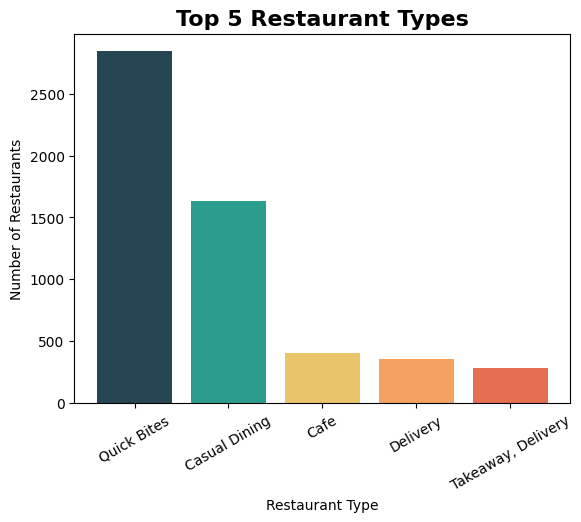

In [14]:
#plt.figure(figsize=(8,8))

plt.bar(
    restaurant_type.index,
    restaurant_type.values,
    color=['#264653', '#2A9D8F', '#E9C46A', '#F4A261', '#E76F51']
)

plt.title("Top 5 Restaurant Types", fontsize=16, fontweight='bold')
plt.xlabel("Restaurant Type")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=30)

plt.show()

This Chart shows that quick bites is top Restaurants type in zomato followed by casual dining and cafe.


<function matplotlib.pyplot.show(close=None, block=None)>

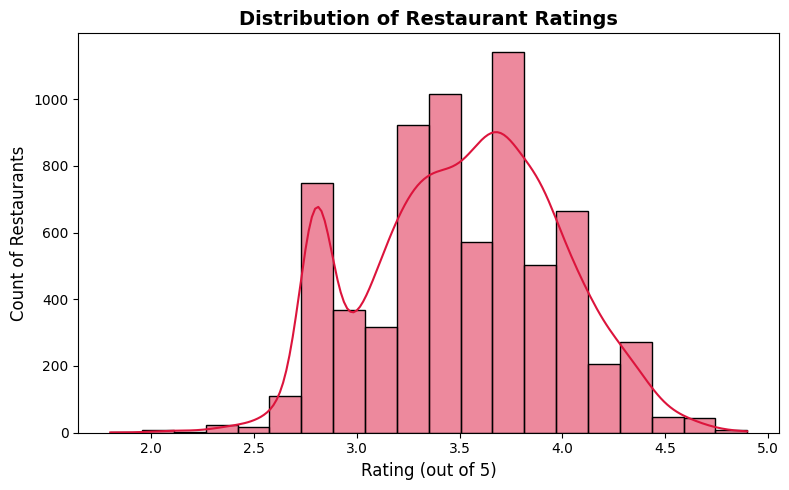

In [15]:
plt.figure(figsize=(8, 5))
df_clean = zomato_df.dropna(subset=['rate (out of 5)', 'avg cost (two people)'])
sns.histplot(df_clean["rate (out of 5)"], bins=20, kde=True, color="crimson")
plt.title("Distribution of Restaurant Ratings", fontsize=14, fontweight="bold")
plt.xlabel("Rating (out of 5)", fontsize=12)
plt.ylabel("Count of Restaurants", fontsize=12)
plt.tight_layout()
plt.show

The chart shows that Zomato ratings follow a bell curve centered around an average of 3.5 out of 5. Most restaurants cluster between 3.2 and 3.9, representing the standard dining experience. Elite restaurants (above 4.5) and poor performers (below 2.5) are rare, meaning breaking into the top tier is highly competitive.

C:\Users\USER\AppData\Local\Temp\ipykernel_16368\2542215669.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='rate (out of 5)',y='online_order',data=df_clean,palette="Set2")


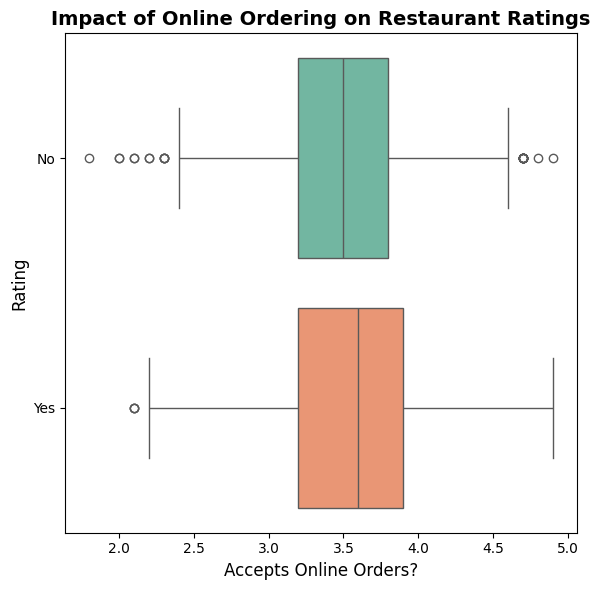

In [16]:
plt.figure(figsize=(6,6))
sns.boxplot(x='rate (out of 5)',y='online_order',data=df_clean,palette="Set2")

plt.title(
    "Impact of Online Ordering on Restaurant Ratings",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Accepts Online Orders?", fontsize=12)
plt.ylabel("Rating", fontsize=12)
plt.tight_layout()
plt.show()

Restaurants that accept online orders (Yes) generally perform better, showing a higher median rating of $3.6$ compared to $3.5$ for those that do not (No). Additionally, the entire box for the online ordering group sits slightly further to the right, meaning customers consistently give higher ratings to restaurants offering delivery convenience.

In [17]:
zomato_df.columns

Index(['restaurant name', 'restaurant type', 'rate (out of 5)',
       'num of ratings', 'avg cost (two people)', 'online_order',
       'table booking', 'cuisines type', 'area', 'local address'],
      dtype='str')

C:\Users\USER\AppData\Local\Temp\ipykernel_16368\3563185537.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_areas.values, y=top_areas.index, palette="viridis",legend=False)


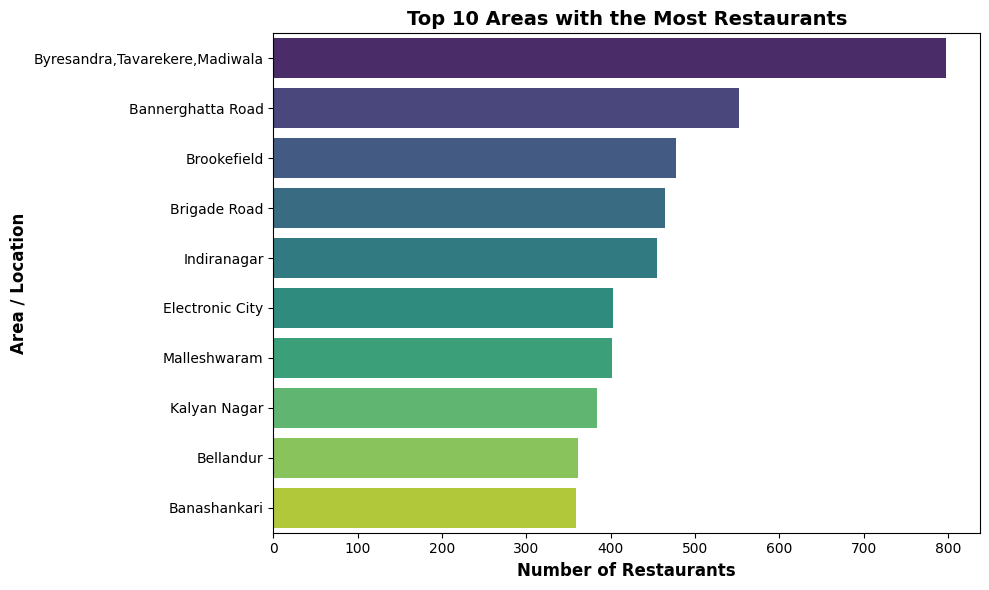

In [18]:
plt.figure(figsize=(10, 6))
top_areas = zomato_df["area"].value_counts().head(10)
sns.barplot(x=top_areas.values, y=top_areas.index, palette="viridis",legend=False)
plt.title(
    "Top 10 Areas with the Most Restaurants", fontsize=14, fontweight="bold"
)
plt.xlabel("Number of Restaurants", fontsize=12,fontweight='bold')
plt.ylabel("Area / Location", fontsize=12,fontweight='bold')
plt.tight_layout()
plt.show()

plt.show()

The chart highlights the major restaurant hotspots across the city. The Byresandra, Tavarekere, Madiwala region is the single largest food hub with nearly 800 restaurants, followed by Bannerghatta Road and Brookefield. This indicates these areas have extremely high consumer demand, making them highly competitive markets for new food businesses, whereas the areas at the bottom of the top 10 have relatively fewer choices.

CHART 4: Relationship Between Cost and Rating

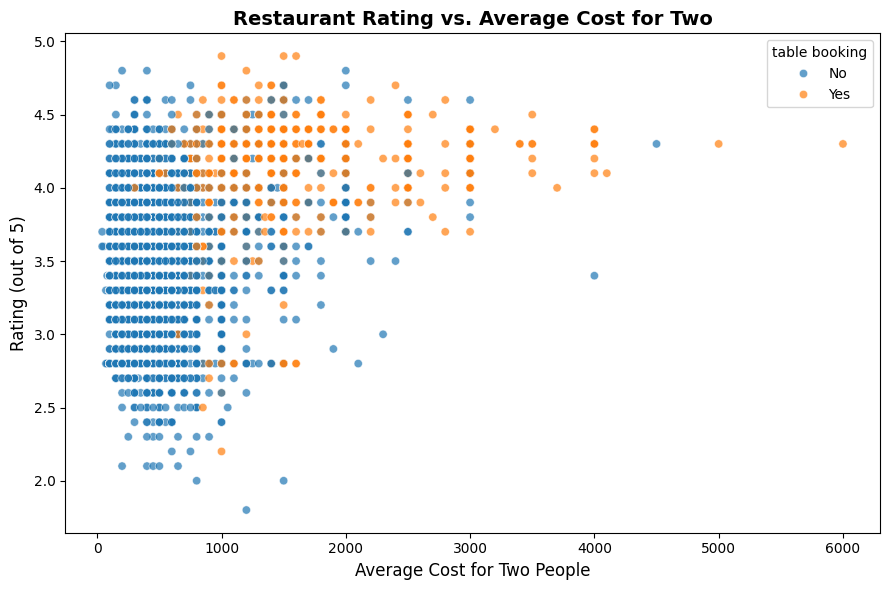

In [31]:
plt.figure(figsize=(9,6))
sns.scatterplot (x='avg cost (two people)',y='rate (out of 5)',data=df_clean,hue="table booking",alpha=0.7)


plt.title(
    "Restaurant Rating vs. Average Cost for Two", fontsize=14, fontweight="bold"
)
plt.xlabel("Average Cost for Two People", fontsize=12)
plt.ylabel("Rating (out of 5)", fontsize=12)
plt.tight_layout()
plt.show()





CHART 5: Average Cost by Restaurant Type

C:\Users\USER\AppData\Local\Temp\ipykernel_16368\3615735848.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cost_by_type.values, y=cost_by_type.index, palette="coolwarm")


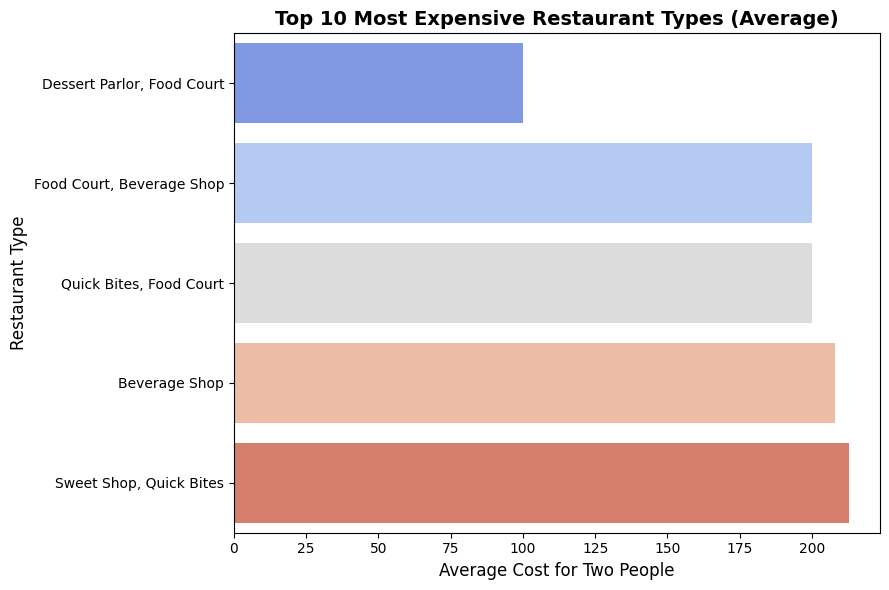

In [43]:
plt.figure(figsize=(9,6))
cost_by_type = (df_clean.groupby('restaurant type')['avg cost (two people)']
.mean()
.sort_values(ascending=True)
.head(5)
)

sns.barplot(x=cost_by_type.values, y=cost_by_type.index, palette="coolwarm")
plt.title(
    "Top 10 Most Expensive Restaurant Types (Average)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Average Cost for Two People", fontsize=12)
plt.ylabel("Restaurant Type", fontsize=12)
plt.tight_layout()
plt.show()


CHART 6: Percentage Share of Table Bookings

In [44]:
zomato_df.columns

Index(['restaurant name', 'restaurant type', 'rate (out of 5)',
       'num of ratings', 'avg cost (two people)', 'online_order',
       'table booking', 'cuisines type', 'area', 'local address'],
      dtype='str')

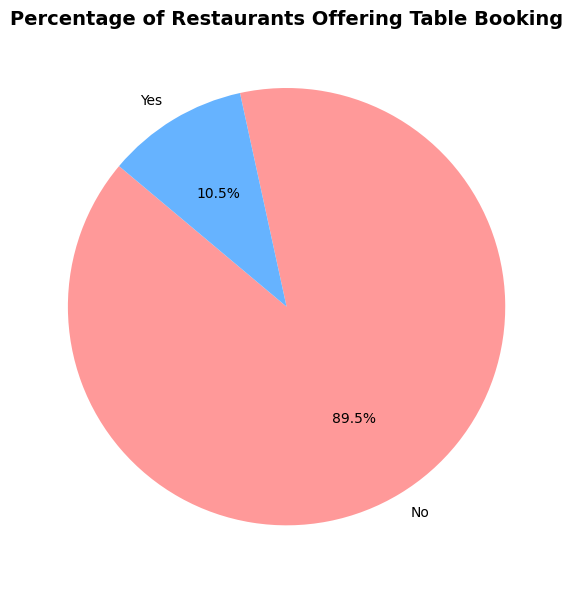

In [62]:
plt.figure(figsize=(9,6))
booking_counts = zomato_df['table booking'].value_counts()
plt.pie (booking_counts,
    labels=booking_counts.index,
    autopct="%1.1f%%",
    startangle=140,
     colors=["#ff9999", "#66b3ff"]
)
plt.title(
    "Percentage of Restaurants Offering Table Booking",
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

CHART 7: Top 10 Most Popular Cuisines

In [50]:
zomato_df.columns

Index(['restaurant name', 'restaurant type', 'rate (out of 5)',
       'num of ratings', 'avg cost (two people)', 'online_order',
       'table booking', 'cuisines type', 'area', 'local address'],
      dtype='str')

C:\Users\USER\AppData\Local\Temp\ipykernel_16368\2606411619.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot (x=top10.values,y=top10.index,palette="magma")


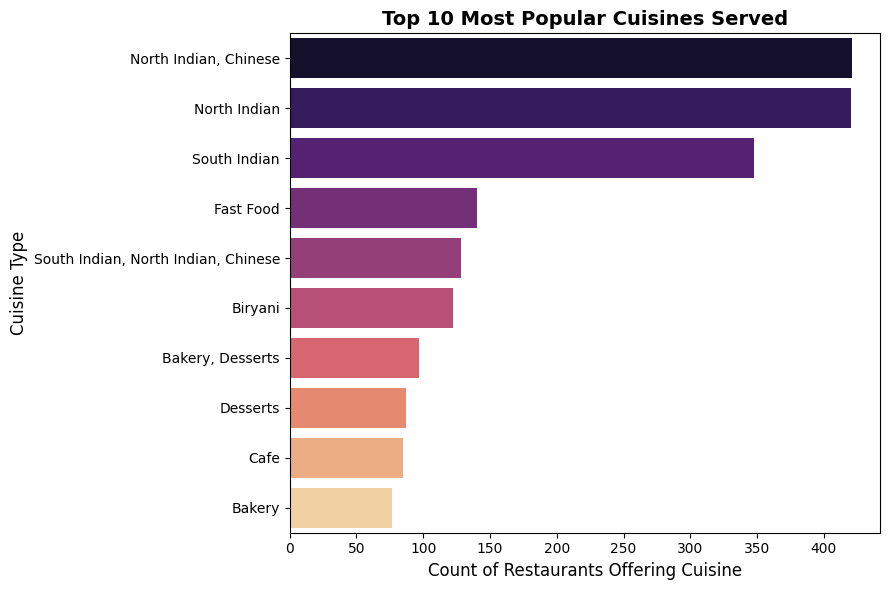

In [ ]:
plt.figure(figsize=(9,6))
all_cuisines = zomato_df['cuisines type'].str.split(" , ").explode().str.strip()
top10 = all_cuisines.value_counts().head(10)

sns.barplot (x=top10.values,y=top10.index,palette="magma")
plt.title("Top 10 Most Popular Cuisines Served", fontsize=14, fontweight="bold")
plt.xlabel("Count of Restaurants Offering Cuisine", fontsize=12)
plt.ylabel("Cuisine Type", fontsize=12)
plt.tight_layout()
plt.show()

C:\Users\USER\AppData\Local\Temp\ipykernel_16368\43541363.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


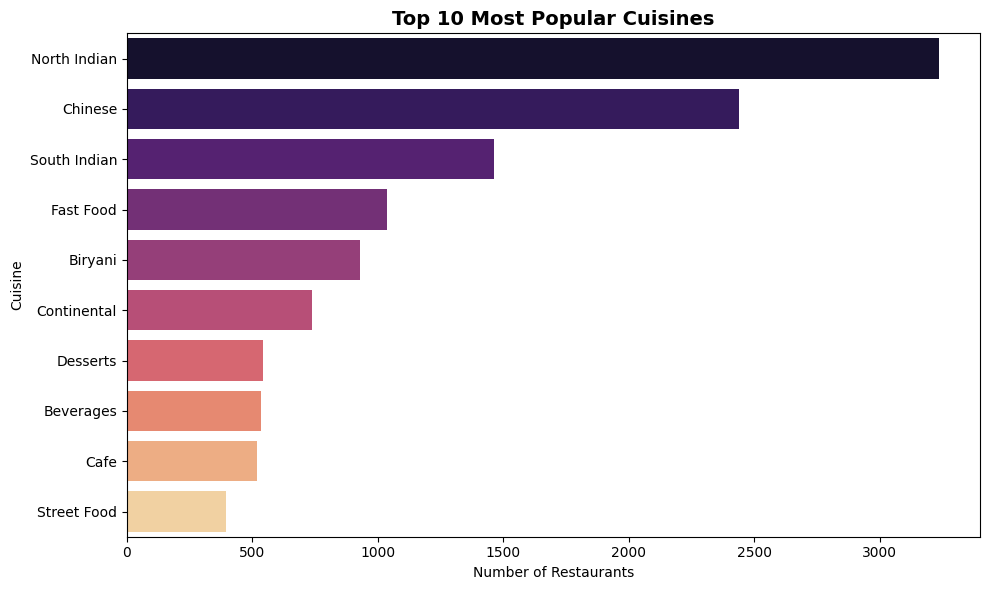